# Project 4: EDA on the Titanic Dataset

**Question:** Which factors affected whether a passenger survived?

| Column | Meaning |
|---|---|
| Survived | 0 = died, 1 = survived |
| Pclass | Ticket class (1 = first, 3 = third) |
| Name, Sex, Age | Passenger details |
| SibSp | Number of siblings or spouses aboard |
| Parch | Number of parents or children aboard |
| Ticket, Fare | Ticket number and price paid |
| Cabin | Cabin number |
| Embarked | Port boarded (C = Cherbourg, Q = Queenstown, S = Southampton) |

In [33]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

#### Loading the raw data

In [34]:
os.makedirs("data/processed", exist_ok=True)
os.makedirs("images", exist_ok=True)

df = pd.read_csv("data/raw/titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### Size and Column types

In [35]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (891, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


#### Statistics for the number columns

In [36]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


#### Statistics for the text columns

In [37]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


#### Checking missing values

In [38]:
missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_table = missing_table.sort_values("missing", ascending=False)
missing_table

,missing,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


#### Checking duplicates and data types

In [39]:
print("Duplicate rows:", df.duplicated().sum())
print("PassengerId is unique:", df['PassengerId'].is_unique)
print()
print(df.dtypes)

Duplicate rows: 0
PassengerId is unique: True

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


#### Picture of the missing values

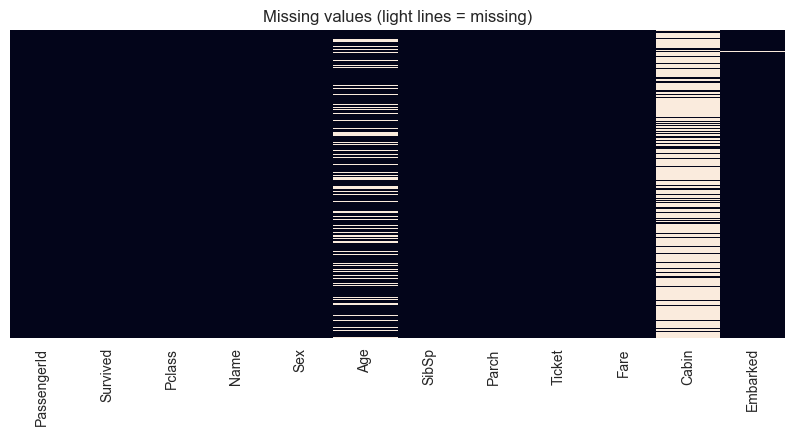

In [40]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing values (light lines = missing)")
plt.savefig("images/missing_values.png", dpi=150, bbox_inches='tight')
plt.show()

#### Cleaning the data

In [41]:
df_clean = df.copy()

# Age: median of the same class and sex
df_clean['Age'] = df_clean.groupby(['Pclass', 'Sex'])['Age'].transform(lambda x: x.fillna(x.median()))

# Embarked: most common port
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# Cabin: keep only whether a cabin was recorded
df_clean['HasCabin'] = df_clean['Cabin'].notnull().astype(int)
df_clean = df_clean.drop(columns=['Cabin'])

# New columns
df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1
df_clean['IsAlone'] = (df_clean['FamilySize'] == 1).astype(int)
df_clean['AgeGroup'] = pd.cut(df_clean['Age'],
                              bins=[0, 12, 18, 35, 60, 100],
                              labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior'])

# Drop columns we don't need
df_clean = df_clean.drop(columns=['PassengerId', 'Name', 'Ticket'])

# Fix data types
df_clean['Sex'] = df_clean['Sex'].astype('category')
df_clean['Embarked'] = df_clean['Embarked'].astype('category')

df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,HasCabin,FamilySize,IsAlone,AgeGroup
0,0,3,male,22.0,1,0,7.2500,S,0,2,0,Young Adult
1,1,1,female,38.0,1,0,71.2833,C,1,2,0,Adult
2,1,3,female,26.0,0,0,7.9250,S,0,1,1,Young Adult
3,1,1,female,35.0,1,0,53.1000,S,1,2,0,Young Adult
4,0,3,male,35.0,0,0,8.0500,S,0,1,1,Young Adult


#### Saving the cleaned data

In [42]:
print("Missing values left:", df_clean.isnull().sum().sum())
print("Shape:", df_clean.shape)
print()
df_clean.info()

df_clean.to_csv("data/processed/titanic_clean.csv", index=False)

Missing values left: 0
Shape: (891, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Survived    891 non-null    int64   
 1   Pclass      891 non-null    int64   
 2   Sex         891 non-null    category
 3   Age         891 non-null    float64 
 4   SibSp       891 non-null    int64   
 5   Parch       891 non-null    int64   
 6   Fare        891 non-null    float64 
 7   Embarked    891 non-null    category
 8   HasCabin    891 non-null    int64   
 9   FamilySize  891 non-null    int64   
 10  IsAlone     891 non-null    int64   
 11  AgeGroup    891 non-null    category
dtypes: category(3), float64(2), int64(7)
memory usage: 65.8 KB


#### Univariate analysis

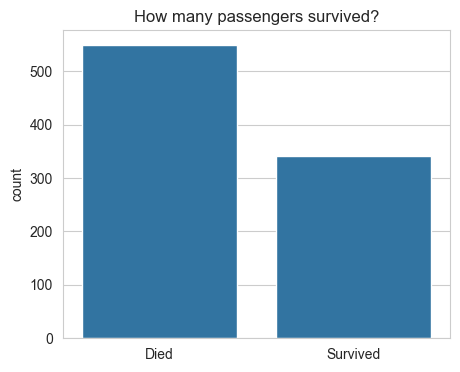

Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


In [43]:
plt.figure(figsize=(5, 4))
sns.countplot(x=df_clean['Survived'].map({0: 'Died', 1: 'Survived'}))
plt.title("How many passengers survived?")
plt.xlabel("")
plt.savefig("images/survival_count.png", dpi=150, bbox_inches='tight')
plt.show()

print((df_clean['Survived'].value_counts(normalize=True) * 100).round(1))

#### numeric columns

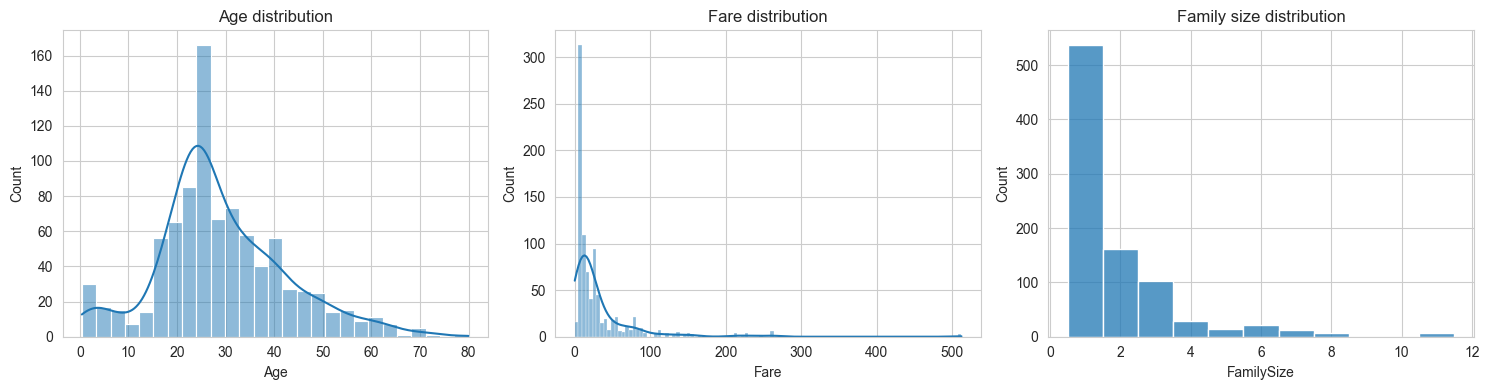

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df_clean['Age'], kde=True, ax=axes[0])
axes[0].set_title("Age distribution")

sns.histplot(df_clean['Fare'], kde=True, ax=axes[1])
axes[1].set_title("Fare distribution")

sns.histplot(df_clean['FamilySize'], discrete=True, ax=axes[2])
axes[2].set_title("Family size distribution")

plt.tight_layout()
plt.savefig("images/numeric_distributions.png", dpi=150, bbox_inches='tight')
plt.show()

#### Categorical Columns

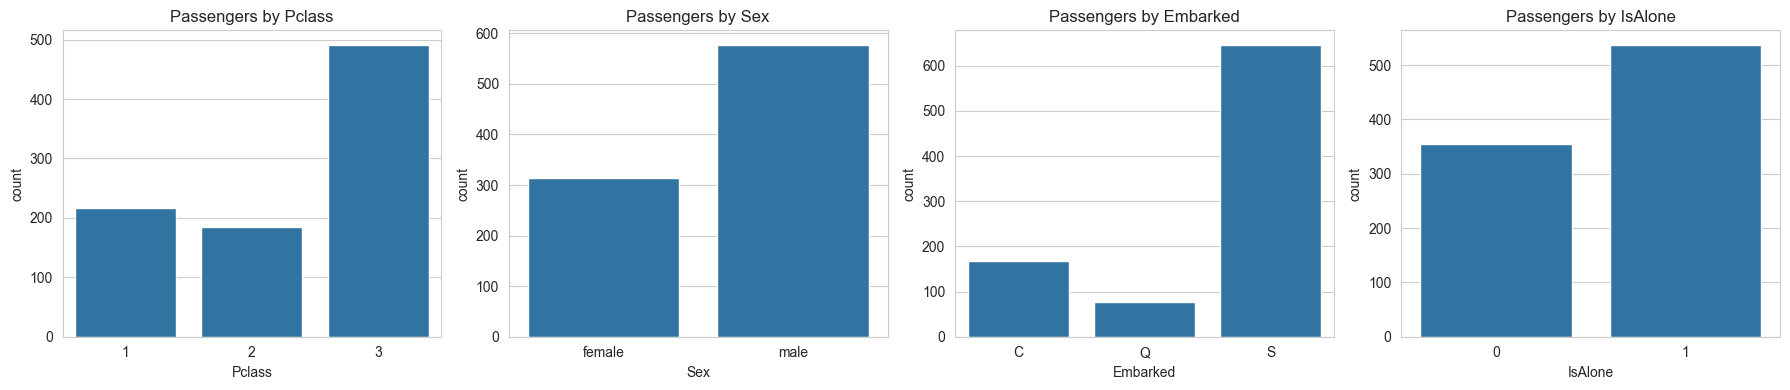

In [45]:
cat_cols = ['Pclass', 'Sex', 'Embarked', 'IsAlone']

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(x=col, data=df_clean, ax=ax)
    ax.set_title("Passengers by " + col)

plt.tight_layout()
plt.savefig("images/categorical_counts.png", dpi=150, bbox_inches='tight')
plt.show()

#### Bivariate and multivariate analysis

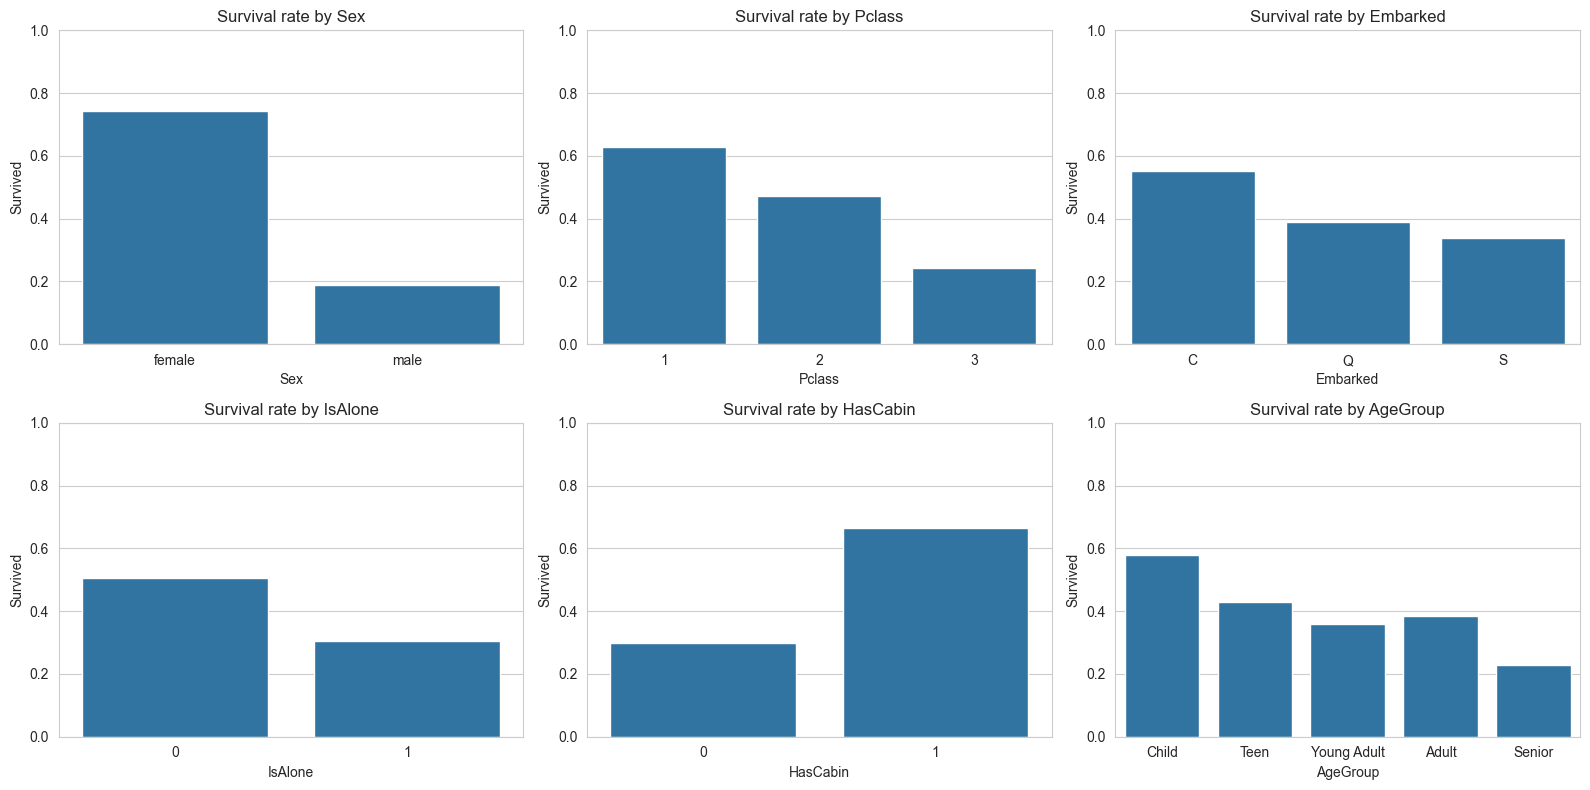

In [46]:
cols = ['Sex', 'Pclass', 'Embarked', 'IsAlone', 'HasCabin', 'AgeGroup']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), cols):
    sns.barplot(x=col, y='Survived', data=df_clean, errorbar=None, ax=ax)
    ax.set_title("Survival rate by " + col)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig("images/survival_rate_by_factor.png", dpi=150, bbox_inches='tight')
plt.show()

#### same numbers as a table

In [47]:
for col in cols:
    print((df_clean.groupby(col, observed=True)['Survived'].mean() * 100).round(1))
    print()

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

Embarked
C    55.4
Q    39.0
S    33.9
Name: Survived, dtype: float64

IsAlone
0    50.6
1    30.4
Name: Survived, dtype: float64

HasCabin
0    30.0
1    66.7
Name: Survived, dtype: float64

AgeGroup
Child          58.0
Teen           42.9
Young Adult    35.8
Adult          38.4
Senior         22.7
Name: Survived, dtype: float64



#### age and fare against survival

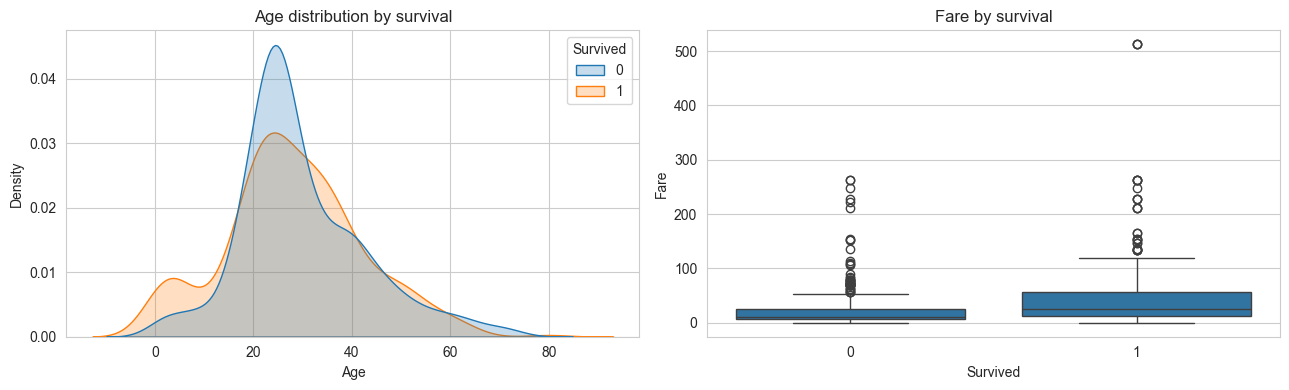

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.kdeplot(data=df_clean, x='Age', hue='Survived', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("Age distribution by survival")

sns.boxplot(data=df_clean, x='Survived', y='Fare', ax=axes[1])
axes[1].set_title("Fare by survival")

plt.tight_layout()
plt.savefig("images/age_fare_vs_survival.png", dpi=150, bbox_inches='tight')
plt.show()

#### multivariate sex and class together

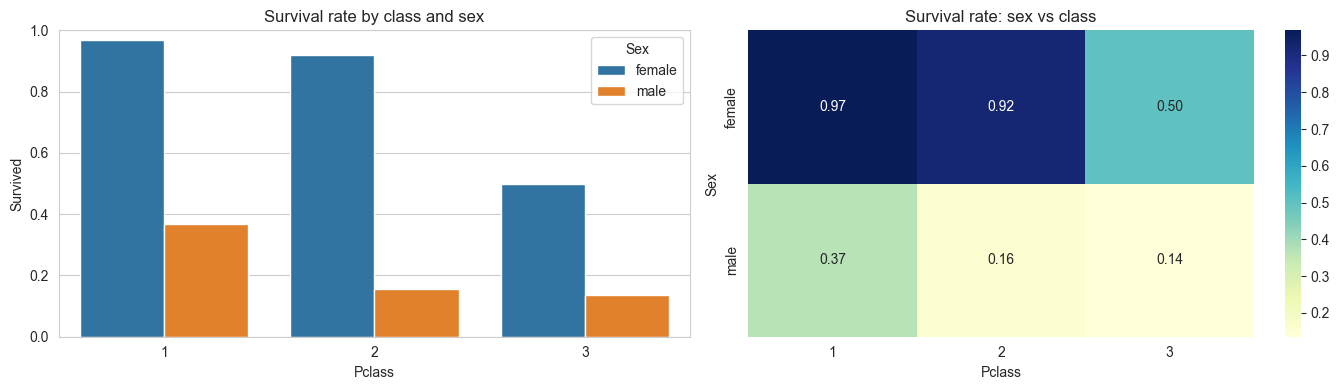

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(x='Pclass', y='Survived', hue='Sex', data=df_clean, errorbar=None, ax=axes[0])
axes[0].set_title("Survival rate by class and sex")
axes[0].set_ylim(0, 1)

pivot = df_clean.pivot_table(values='Survived', index='Sex', columns='Pclass',
                             aggfunc='mean', observed=True)
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[1])
axes[1].set_title("Survival rate: sex vs class")

plt.tight_layout()
plt.savefig("images/sex_class_survival.png", dpi=150, bbox_inches='tight')
plt.show()

#### an interactive plotly chart

In [50]:
outcome = df_clean['Survived'].map({0: 'Died', 1: 'Survived'})

fig = px.scatter(df_clean, x='Age', y='Fare', color=outcome, facet_col='Sex',
                 opacity=0.6, labels={'color': 'Outcome'},
                 title="Age vs Fare by sex and outcome")
fig.show()

#### Outliers (boxplot and IQR)

In [51]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((series < lower) | (series > upper)).sum()
    return lower, upper, count

for col in ['Age', 'Fare', 'FamilySize']:
    lower, upper, count = iqr_bounds(df_clean[col])
    print(f"{col}: lower bound = {lower:.2f}, upper bound = {upper:.2f}, outliers = {count}")

Age: lower bound = -0.25, upper bound = 57.75, outliers = 33
Fare: lower bound = -26.72, upper bound = 65.63, outliers = 116
FamilySize: lower bound = -0.50, upper bound = 3.50, outliers = 91


#### Boxplot

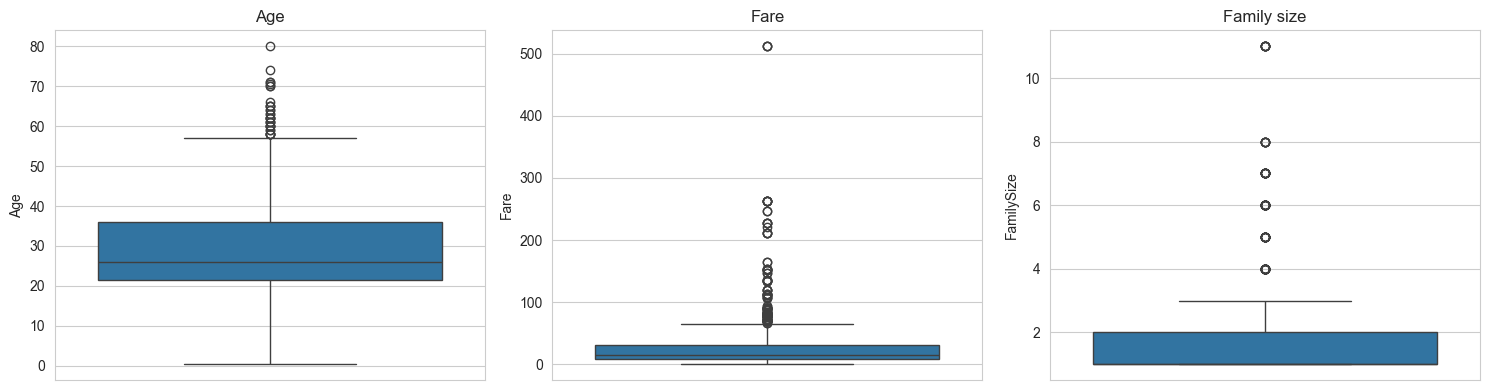

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=df_clean['Age'], ax=axes[0])
axes[0].set_title("Age")

sns.boxplot(y=df_clean['Fare'], ax=axes[1])
axes[1].set_title("Fare")

sns.boxplot(y=df_clean['FamilySize'], ax=axes[2])
axes[2].set_title("Family size")

plt.tight_layout()
plt.savefig("images/outlier_boxplots.png", dpi=150, bbox_inches='tight')
plt.show()

Decision: Keep the outliers.

Reason:

High fares belong to real first-class passengers who bought expensive tickets/suites. Removing them would hide important information about wealth and survival.

Large families really existed on the ship (parents traveling with many children).

Conclusion: Since these are real historical facts and not data mistakes, keeping them makes our analysis more accurate.

#### Correlation heatmap

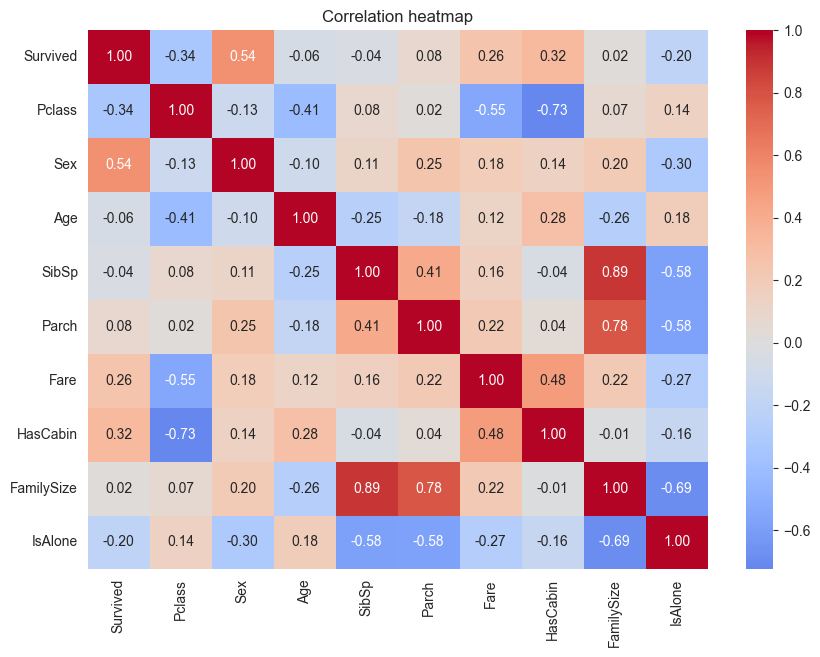

In [53]:
df_corr = df_clean[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
                    'Fare', 'HasCabin', 'FamilySize', 'IsAlone']].copy()
df_corr['Sex'] = df_corr['Sex'].astype(str).map({'male': 0, 'female': 1})

corr = df_corr.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Correlation heatmap")
plt.savefig("images/correlation_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

#### correlation with survival, sorted

In [54]:
corr['Survived'].drop('Survived').sort_values()

Pclass       -0.338481
IsAlone      -0.203367
Age          -0.059579
SibSp        -0.035322
FamilySize    0.016639
Parch         0.081629
Fare          0.257307
HasCabin      0.316912
Sex           0.543351
Name: Survived, dtype: float64

#### Key numbers and insights

In [55]:
print("Overall survival rate:", round(df_clean['Survived'].mean() * 100, 1), "%")
print()
for col in ['Sex', 'Pclass', 'IsAlone', 'HasCabin', 'AgeGroup', 'Embarked']:
    print((df_clean.groupby(col, observed=True)['Survived'].mean() * 100).round(1))
    print()

Overall survival rate: 38.4 %

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

IsAlone
0    50.6
1    30.4
Name: Survived, dtype: float64

HasCabin
0    30.0
1    66.7
Name: Survived, dtype: float64

AgeGroup
Child          58.0
Teen           42.9
Young Adult    35.8
Adult          38.4
Senior         22.7
Name: Survived, dtype: float64

Embarked
C    55.4
Q    39.0
S    33.9
Name: Survived, dtype: float64



## Key insights
Overall, 38.4% of passengers survived.

Sex: 74.2% of women survived compared with 18.9% of men.

Class: survival was 63.0% in first class, 47.3% in second and 24.2% in third.

Age: children (under 12) survived at 58.0%, compared with ~36% for adults.

Travelling alone: 30.4% of solo passengers survived, compared with 50.6% of those with family.

Cabin: passengers with a recorded cabin survived at 66.7%, compared with 30.0% without.

Sex and class together: First-class women had the highest survival rate, while third-class passengers (especially men) had the lowest.

## Conclusion
The factors that mattered most for survival were sex, passenger class and cabin availability.